In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
from lib import GDRegressor, SGDRegressor, MiniBatchGDRegressor
%matplotlib inline

def plot_contour_loss(X_train, y_train, models_dict, feature_names=None, feat_idx1=0, feat_idx2=1, title="Loss Contour Plot"):
    X_train = np.asarray(X_train)
    y_train = np.asarray(y_train)
    
    f1_name = feature_names[feat_idx1] if feature_names is not None else f"Feature {feat_idx1}"
    f2_name = feature_names[feat_idx2] if feature_names is not None else f"Feature {feat_idx2}"
    
    all_w1, all_w2 = [], []
    for model in models_dict.values():
        if hasattr(model, 'coef_history_') and len(model.coef_history_) > 0:
            hist = np.array(model.coef_history_)
            all_w1.extend(hist[:, feat_idx1])
            all_w2.extend(hist[:, feat_idx2])
        else:
            all_w1.append(model.coef_[feat_idx1])
            all_w2.append(model.coef_[feat_idx2])
            
    all_w1.append(0.0)
    all_w2.append(0.0)
    
    w1_min, w1_max = min(all_w1) - 1.0, max(all_w1) + 1.0
    w2_min, w2_max = min(all_w2) - 1.0, max(all_w2) + 1.0
    
    w1_vals = np.linspace(w1_min, w1_max, 100)
    w2_vals = np.linspace(w2_min, w2_max, 100)
    W1, W2 = np.meshgrid(w1_vals, w2_vals)
    
    base_coef = np.mean([model.coef_ for model in models_dict.values()], axis=0)
    base_intercept = np.mean([model.intercept_ for model in models_dict.values()])
    
    Z = np.zeros(W1.shape)
    for i in range(W1.shape[0]):
        for j in range(W1.shape[1]):
            temp_coef = base_coef.copy()
            temp_coef[feat_idx1] = W1[i, j]
            temp_coef[feat_idx2] = W2[i, j]
            y_pred = np.dot(X_train, temp_coef) + base_intercept
            Z[i, j] = np.mean((y_train - y_pred) ** 2)
            
    plt.figure(figsize=(9, 6))
    contour = plt.contourf(W1, W2, Z, levels=30, cmap='viridis', alpha=0.85)
    plt.colorbar(contour, label='MSE Loss')
    plt.contour(W1, W2, Z, levels=15, colors='white', alpha=0.3, linewidths=0.8)
    
    styles = {
        'GDRegressor': {'color': 'red', 'marker': 'o', 'linestyle': '-'},
        'SGDRegressor': {'color': 'cyan', 'marker': 's', 'linestyle': '--'},
        'MiniBatchGDRegressor': {'color': 'orange', 'marker': '^', 'linestyle': '-.'}
    }
    
    for name, model in models_dict.items():
        if hasattr(model, 'coef_history_') and len(model.coef_history_) > 0:
            hist = np.array(model.coef_history_)
            w1_hist = hist[:, feat_idx1]
            w2_hist = hist[:, feat_idx2]
            st = styles.get(name, {'color': 'white', 'marker': 'o', 'linestyle': '-'})
            plt.plot(w1_hist, w2_hist, label=f"{name} Trajectory", color=st['color'],
                     linewidth=2, linestyle=st['linestyle'], alpha=0.9)
            plt.scatter(w1_hist[0], w2_hist[0], color='lightgreen', s=60, zorder=5)
            plt.scatter(w1_hist[-1], w2_hist[-1], color=st['color'], s=100, edgecolors='black', zorder=6, label=f"{name} Final")
            
    plt.xlabel(f"Weight w_{feat_idx1} ({f1_name})", fontsize=11)
    plt.ylabel(f"Weight w_{feat_idx2} ({f2_name})", fontsize=11)
    plt.title(title, fontsize=13, fontweight='bold')
    plt.legend(loc='best')
    plt.grid(True, linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()


# Advertising Dataset

In [28]:
df_adv = pd.read_csv('advertising.csv')
df_adv.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [29]:
df_adv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [30]:
df_adv.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


In [31]:
X_adv = df_adv.drop(columns=['Sales'])
y_adv = df_adv['Sales']

X_train_adv, X_test_adv, y_train_adv, y_test_adv = train_test_split(X_adv, y_adv, test_size=0.2, random_state=42)

scaler_adv = StandardScaler()
X_train_adv = scaler_adv.fit_transform(X_train_adv)
X_test_adv = scaler_adv.transform(X_test_adv)

models_adv = {
    'GDRegressor': GDRegressor(lr=0.01, epochs=100),
    'SGDRegressor': SGDRegressor(lr=0.01, epochs=100),
    'MiniBatchGDRegressor': MiniBatchGDRegressor(batch_size=35, lr=0.01, epochs=100)
}

for name, model in models_adv.items():
    model.fit(X_train_adv, y_train_adv)
    y_pred = model.predict(X_test_adv)
    print(f"====== {name} ======")
    print("R2 score: ", r2_score(y_test_adv, y_pred))
    print("RMSE score: ", root_mean_squared_error(y_test_adv, y_pred))
    print("MAE score: ", mean_absolute_error(y_test_adv, y_pred))

====== GDRegressor ======
R2 score:  0.8177176778843405
RMSE score:  2.373336104290374
MAE score:  1.9834859922315005
====== SGDRegressor ======
R2 score:  0.8776435519473338
RMSE score:  1.944466208737052
MAE score:  1.5032676707306138
====== MiniBatchGDRegressor ======
R2 score:  0.9057137907288021
RMSE score:  1.7069117087038252
MAE score:  1.2768850082026095


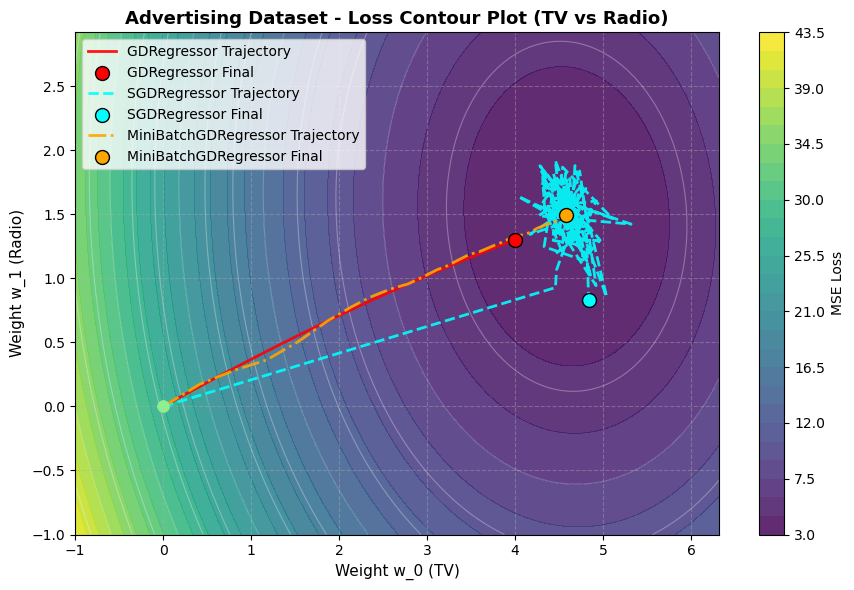

In [32]:
plot_contour_loss(X_train_adv, y_train_adv, models_adv, feature_names=X_adv.columns, feat_idx1=0, feat_idx2=1, title='Advertising Dataset - Loss Contour Plot (TV vs Radio)')


# Boston Dataset

In [33]:
df_bos = pd.read_csv('Boston.csv')
if 'Unnamed: 0' in df_bos.columns:
    df_bos = df_bos.drop(columns=['Unnamed: 0'])
df_bos.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [34]:
df_bos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  black    506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


In [35]:
df_bos.describe()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [36]:
X_bos = df_bos.drop(columns=['medv'])
y_bos = df_bos['medv']

X_train_bos, X_test_bos, y_train_bos, y_test_bos = train_test_split(X_bos, y_bos, test_size=0.2, random_state=42)

scaler_bos = StandardScaler()
X_train_bos = scaler_bos.fit_transform(X_train_bos)
X_test_bos = scaler_bos.transform(X_test_bos)

models_bos = {
    'GDRegressor': GDRegressor(lr=0.01, epochs=100),
    'SGDRegressor': SGDRegressor(lr=0.01, epochs=100),
    'MiniBatchGDRegressor': MiniBatchGDRegressor(batch_size=35, lr=0.01, epochs=100)
}

for name, model in models_bos.items():
    model.fit(X_train_bos, y_train_bos)
    y_pred = model.predict(X_test_bos)
    print(f"====== {name} ======")
    print("R2 score: ", r2_score(y_test_bos, y_pred))
    print("RMSE score: ", root_mean_squared_error(y_test_bos, y_pred))
    print("MAE score: ", mean_absolute_error(y_test_bos, y_pred))

====== GDRegressor ======
R2 score:  0.4831683295933532
RMSE score:  6.156396807223243
MAE score:  3.9148480327175617
====== SGDRegressor ======
R2 score:  0.589898860303752
RMSE score:  5.484001098858931
MAE score:  3.6765006356240515
====== MiniBatchGDRegressor ======
R2 score:  0.6651976958384317
RMSE score:  4.955029724932126
MAE score:  3.209078775782448


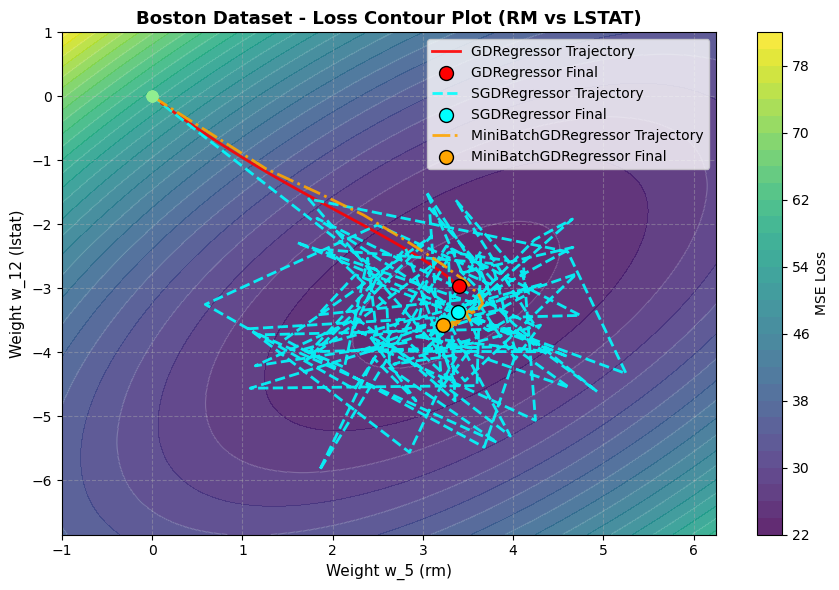

In [37]:
plot_contour_loss(X_train_bos, y_train_bos, models_bos, feature_names=X_bos.columns, feat_idx1=5, feat_idx2=12, title='Boston Dataset - Loss Contour Plot (RM vs LSTAT)')


# Auto MPG Dataset

In [38]:
df_mpg = pd.read_csv('auto-mpg[1].csv')
df_mpg['horsepower'] = pd.to_numeric(df_mpg['horsepower'], errors='coerce')
df_mpg['horsepower'] = df_mpg['horsepower'].fillna(df_mpg['horsepower'].median())
if 'car name' in df_mpg.columns:
    df_mpg = df_mpg.drop(columns=['car name'])
df_mpg.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
0,18.0,8,307.0,130.0,3504,12.0,70,1
1,15.0,8,350.0,165.0,3693,11.5,70,1
2,18.0,8,318.0,150.0,3436,11.0,70,1
3,16.0,8,304.0,150.0,3433,12.0,70,1
4,17.0,8,302.0,140.0,3449,10.5,70,1


In [39]:
df_mpg.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
dtypes: float64(4), int64(4)
memory usage: 25.0 KB


In [40]:
df_mpg.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.304020,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,38.222625,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,76.000000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,125.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


In [41]:
X_mpg = df_mpg.drop(columns=['mpg'])
y_mpg = df_mpg['mpg']

X_train_mpg, X_test_mpg, y_train_mpg, y_test_mpg = train_test_split(X_mpg, y_mpg, test_size=0.2, random_state=42)

scaler_mpg = StandardScaler()
X_train_mpg = scaler_mpg.fit_transform(X_train_mpg)
X_test_mpg = scaler_mpg.transform(X_test_mpg)

models_mpg = {
    'GDRegressor': GDRegressor(lr=0.01, epochs=100),
    'SGDRegressor': SGDRegressor(lr=0.01, epochs=100),
    'MiniBatchGDRegressor': MiniBatchGDRegressor(batch_size=35, lr=0.01, epochs=100)
}

for name, model in models_mpg.items():
    model.fit(X_train_mpg, y_train_mpg)
    y_pred = model.predict(X_test_mpg)
    print(f"====== {name} ======")
    print("R2 score: ", r2_score(y_test_mpg, y_pred))
    print("RMSE score: ", root_mean_squared_error(y_test_mpg, y_pred))
    print("MAE score: ", mean_absolute_error(y_test_mpg, y_pred))

====== GDRegressor ======
R2 score:  0.6172170827873156
RMSE score:  4.5366150582539735
MAE score:  3.6297051602552686
====== SGDRegressor ======
R2 score:  0.8335764564650707
RMSE score:  2.9913211282218515
MAE score:  2.3365267646935854
====== MiniBatchGDRegressor ======
R2 score:  0.841824796931466
RMSE score:  2.9162507022595237
MAE score:  2.2793620708300657


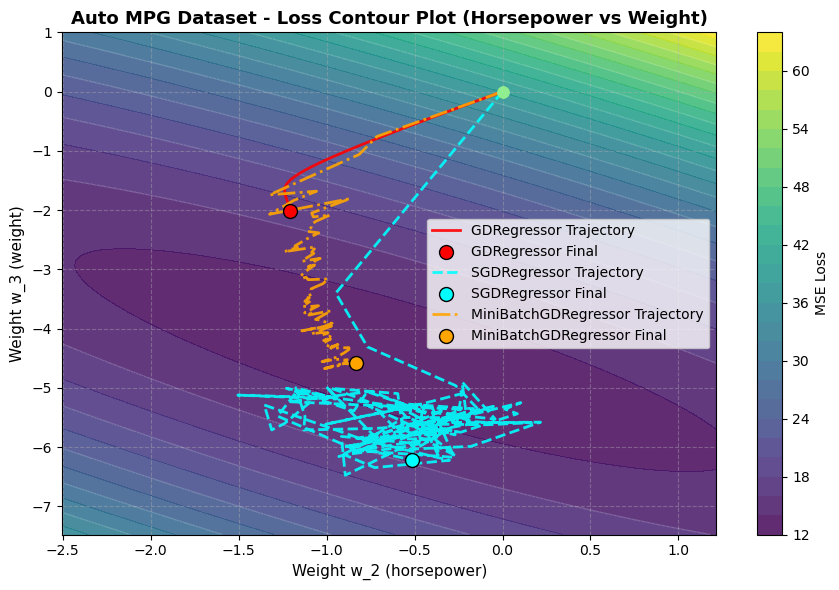

In [42]:
plot_contour_loss(X_train_mpg, y_train_mpg, models_mpg, feature_names=X_mpg.columns, feat_idx1=2, feat_idx2=3, title='Auto MPG Dataset - Loss Contour Plot (Horsepower vs Weight)')


# Diabetes Dataset

In [43]:
df_diab = pd.read_csv('diabetes[1].csv')
df_diab.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [44]:
df_diab.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [45]:
df_diab.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [46]:
X_diab = df_diab.drop(columns=['BloodPressure'])
y_diab = df_diab['BloodPressure']

X_train_diab, X_test_diab, y_train_diab, y_test_diab = train_test_split(X_diab, y_diab, test_size=0.2, random_state=42)

scaler_diab = StandardScaler()
X_train_diab = scaler_diab.fit_transform(X_train_diab)
X_test_diab = scaler_diab.transform(X_test_diab)

models_diab = {
    'GDRegressor': GDRegressor(lr=0.01, epochs=100),
    'SGDRegressor': SGDRegressor(lr=0.01, epochs=100),
    'MiniBatchGDRegressor': MiniBatchGDRegressor(batch_size=35, lr=0.01, epochs=100)
}

for name, model in models_diab.items():
    model.fit(X_train_diab, y_train_diab)
    y_pred = model.predict(X_test_diab)
    print(f"====== {name} ======")
    print("R2 score: ", r2_score(y_test_diab, y_pred))
    print("RMSE score: ", root_mean_squared_error(y_test_diab, y_pred))
    print("MAE score: ", mean_absolute_error(y_test_diab, y_pred))

====== GDRegressor ======
R2 score:  0.09417032037898476
RMSE score:  21.278396500210135
MAE score:  15.699760736415083
====== SGDRegressor ======
R2 score:  0.0661105394434719
RMSE score:  21.605452235129903
MAE score:  14.774189847459349
====== MiniBatchGDRegressor ======
R2 score:  0.19335492503663132
RMSE score:  20.079683697532925
MAE score:  12.592913013172943


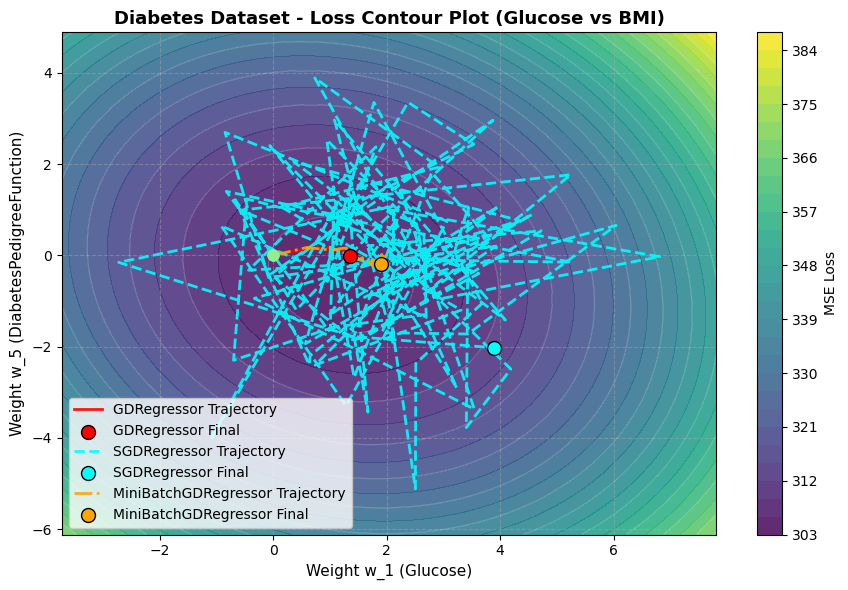

In [47]:
plot_contour_loss(X_train_diab, y_train_diab, models_diab, feature_names=X_diab.columns, feat_idx1=1, feat_idx2=5, title='Diabetes Dataset - Loss Contour Plot (Glucose vs BMI)')


# California Housing Dataset

In [48]:
df_housing = pd.read_csv('housing[1].csv')
df_housing['total_bedrooms'] = df_housing['total_bedrooms'].fillna(df_housing['total_bedrooms'].median())
df_housing = pd.get_dummies(df_housing, columns=['ocean_proximity'], drop_first=True)
df_housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,False,False,True,False
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,False,False,True,False
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,False,False,True,False
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,False,False,True,False
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,False,False,True,False


In [49]:
df_housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   longitude                   20640 non-null  float64
 1   latitude                    20640 non-null  float64
 2   housing_median_age          20640 non-null  float64
 3   total_rooms                 20640 non-null  float64
 4   total_bedrooms              20640 non-null  float64
 5   population                  20640 non-null  float64
 6   households                  20640 non-null  float64
 7   median_income               20640 non-null  float64
 8   median_house_value          20640 non-null  float64
 9   ocean_proximity_INLAND      20640 non-null  bool   
 10  ocean_proximity_ISLAND      20640 non-null  bool   
 11  ocean_proximity_NEAR BAY    20640 non-null  bool   
 12  ocean_proximity_NEAR OCEAN  20640 non-null  bool   
dtypes: bool(4), float64(9)
memory u

In [50]:
df_housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,536.838857,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,419.391878,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,297.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,643.250000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [51]:
X_house = df_housing.drop(columns=['median_house_value'])
y_house = df_housing['median_house_value']

X_train_house, X_test_house, y_train_house, y_test_house = train_test_split(X_house, y_house, test_size=0.2, random_state=42)

scaler_house = StandardScaler()
X_train_house = scaler_house.fit_transform(X_train_house)
X_test_house = scaler_house.transform(X_test_house)

models_house = {
    'GDRegressor': GDRegressor(lr=0.01, epochs=200),
    'SGDRegressor': SGDRegressor(lr=1e-5, epochs=20),
    'MiniBatchGDRegressor': MiniBatchGDRegressor(batch_size=64, lr=5e-5, epochs=100)
}

for name, model in models_house.items():
    model.fit(X_train_house, y_train_house)
    y_pred = model.predict(X_test_house)
    print(f"====== {name} ======")
    print("R2 score: ", r2_score(y_test_house, y_pred))
    print("RMSE score: ", root_mean_squared_error(y_test_house, y_pred))
    print("MAE score: ", mean_absolute_error(y_test_house, y_pred))

====== GDRegressor ======
R2 score:  0.6093098668591719
RMSE score:  71551.64974882646
MAE score:  51006.84711752259
====== SGDRegressor ======
R2 score:  0.6168144432020035
RMSE score:  70861.11726189003
MAE score:  51095.092764660745
====== MiniBatchGDRegressor ======
R2 score:  0.5847616592869291
RMSE score:  73765.30687120212
MAE score:  50964.49057353871


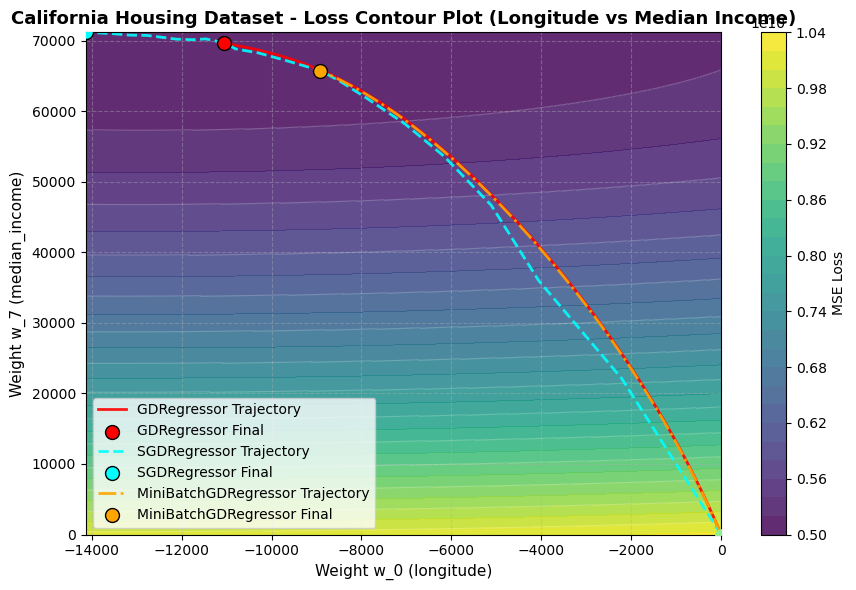

In [52]:
plot_contour_loss(X_train_house, y_train_house, models_house, feature_names=X_house.columns, feat_idx1=0, feat_idx2=7, title='California Housing Dataset - Loss Contour Plot (Longitude vs Median Income)')
